In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
model_name = "FlameF0X/TinyMoE-100m-2x8-retrained"
model_slug = model_name.replace("/", "_")

model_figures_dir = FIGURES_DIR / model_slug
model_figures_dir.mkdir(parents=True, exist_ok=True)

In [9]:
diagnos_path = f"../results/diagnostics_{model_slug}.csv"
d_df = pd.read_csv(diagnos_path)
d_df.head()

,sequence,position,layer,kl_0,kl_1,kl_2,delta_1,delta_2
0,0,0,0,5.129023,0.000018,0.000001,5.129004,0.000017
1,0,1,0,2.799886,0.000623,0.000002,2.799263,0.000621
2,0,2,0,4.627536,0.000464,0.000002,4.627072,0.000463
3,0,3,0,7.084110,0.000038,0.000007,7.084072,0.000031
4,0,4,0,3.589844,0.000344,0.000006,3.589499,0.000338


In [10]:
print(
    f"\nNum tokens: {d_df.shape[0]}"
    f"\nNum sequences: {d_df['sequence'].nunique()}"
    f"\nNum batches: {d_df['position'].nunique()}"
    f"\nNum layers: {d_df['layer'].nunique()}")


Num tokens: 256000
Num sequences: 100
Num batches: 256
Num layers: 10


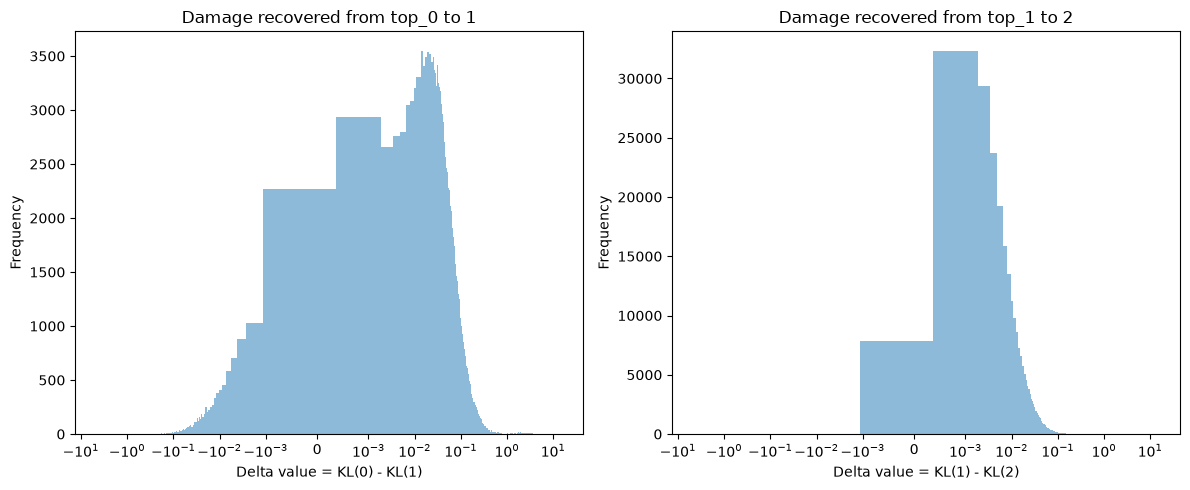

In [12]:
def plot_deltas_histogram(d_df, save_path=None):

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes = axes.flatten()

    kl_cols = ["delta_1", "delta_2"]
    kl_values = d_df[kl_cols]
    edges = np.histogram_bin_edges(kl_values.values.flatten(), bins="fd")

    for ax, col in zip(axes, ["delta_1", "delta_2"]):
        ax.set_xscale("symlog", linthresh=1e-3)
        d_df[col].plot.hist(bins=edges, alpha=0.5, label=f"Delta for {col}", ax=ax)
        ax.set_title(f"Damage recovered from top_{int(col.split('_')[1]) - 1} to {int(col.split('_')[1])}")
        ax.set_xlabel(f"Delta value = KL({int(col.split('_')[1]) - 1}) - KL({col.split('_')[1]})")
        ax.set_ylabel("Frequency")
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path)

    plt.show()

plot_deltas_histogram(d_df, save_path=f"{model_figures_dir}/deltas_histogram.png")

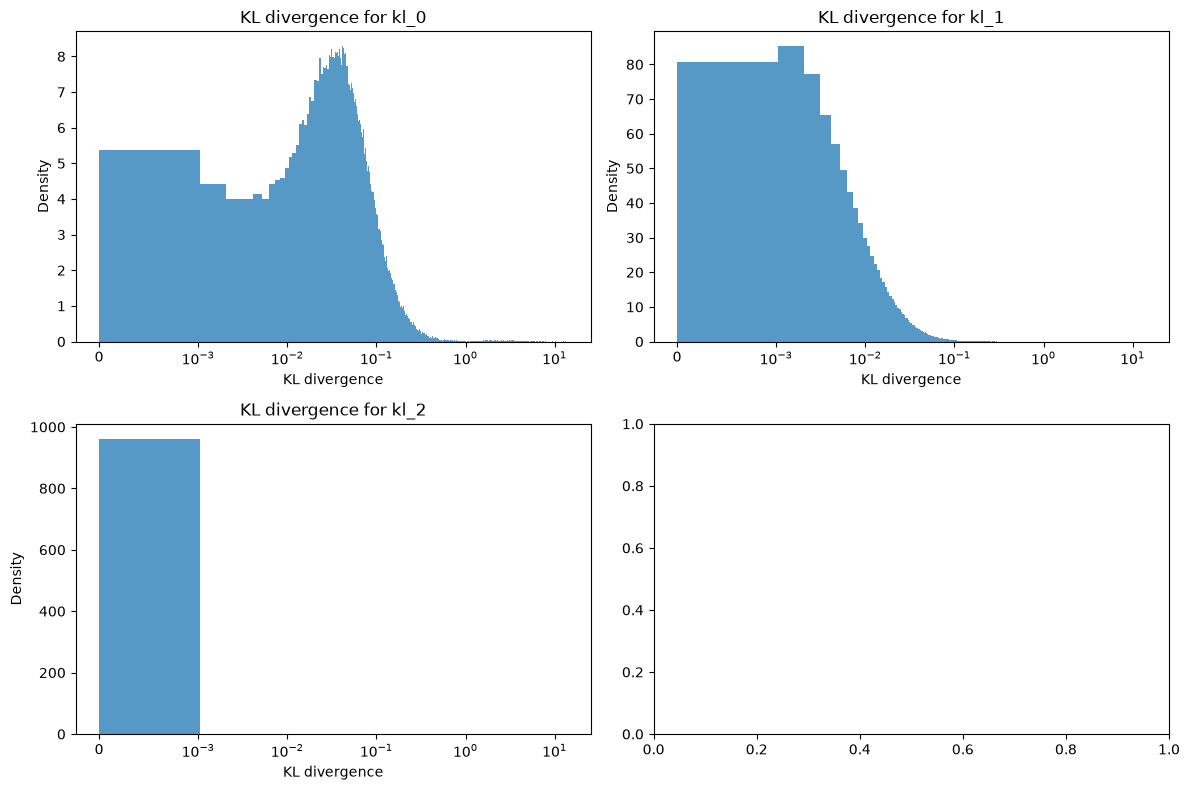

In [13]:
def plot_kl_divergence_histograms(d_df, save_path=None):
    fig, axes = plt.subplots(figsize=(12, 8), nrows=2, ncols=2)

    axes = axes.flatten()
    kl_cols = ["kl_0", "kl_1", "kl_2"]
    kl_values = d_df[kl_cols]

    edges = np.histogram_bin_edges(kl_values.values.flatten(), bins="fd")

    for ax, col in zip(axes, kl_cols):
        ax.set_xscale("symlog", linthresh=1e-3)
        d_df[col].plot.hist(bins=edges, alpha=0.75, density=True, label=f"KL divergence for {col}", ax=ax)
        ax.set_title(f"KL divergence for {col}")
        ax.set_xlabel("KL divergence")
        ax.set_ylabel("Density")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()

plot_kl_divergence_histograms(d_df, save_path=f"{model_figures_dir}/kl_divergence_histograms.png")

In [14]:
percent_tokens_with_low_delta_2 =\
      d_df[d_df["delta_2"] < 0.01].shape[0] / d_df.shape[0]* 100
print(f"\nPercentage of tokens with delta_2 < 0.01: {percent_tokens_with_low_delta_2:.2f}%")

percent_tokens_with_high_delta_2 =\
      d_df[d_df["delta_2"] > 0.05].shape[0] / d_df.shape[0]* 100
print(f"\nPercentage of tokens with delta_2 > 0.05: {percent_tokens_with_high_delta_2:.2f}%")

# per layer analysis, we can group by layer and compute the mean delta_2 for each layer
layer_mean_delta_2 = d_df.groupby("layer")["delta_2"].mean()
print("\nMean delta_2 per layer:")
print(layer_mean_delta_2)


Percentage of tokens with delta_2 < 0.01: 57.15%

Percentage of tokens with delta_2 > 0.05: 6.61%

Mean delta_2 per layer:
layer
0    0.006723
1    0.026933
2    0.020846
3    0.017974
4    0.014740
5    0.015173
6    0.014741
7    0.017043
8    0.015763
9    0.017809
Name: delta_2, dtype: float64


In [15]:
def plot_histograms_per_layer(d_df, col="delta_2", save_path=None):
    fig, axes = plt.subplots(3, 4, figsize=(15, 10))
    for ax, layer in zip(axes.flat, d_df["layer"].unique()):
        layer_data = d_df[d_df["layer"] == layer]
        edges = np.histogram_bin_edges(layer_data[col], bins="fd")
        ax.hist(layer_data[col], bins=edges, alpha=0.7)
        ax.set_title(f"Histogram of {col} for layer {layer}")
        ax.set_xlabel(col)
        ax.set_ylabel("Frequency")
        ax.grid()
        ax.set_xscale("symlog", linthresh=1e-3)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()

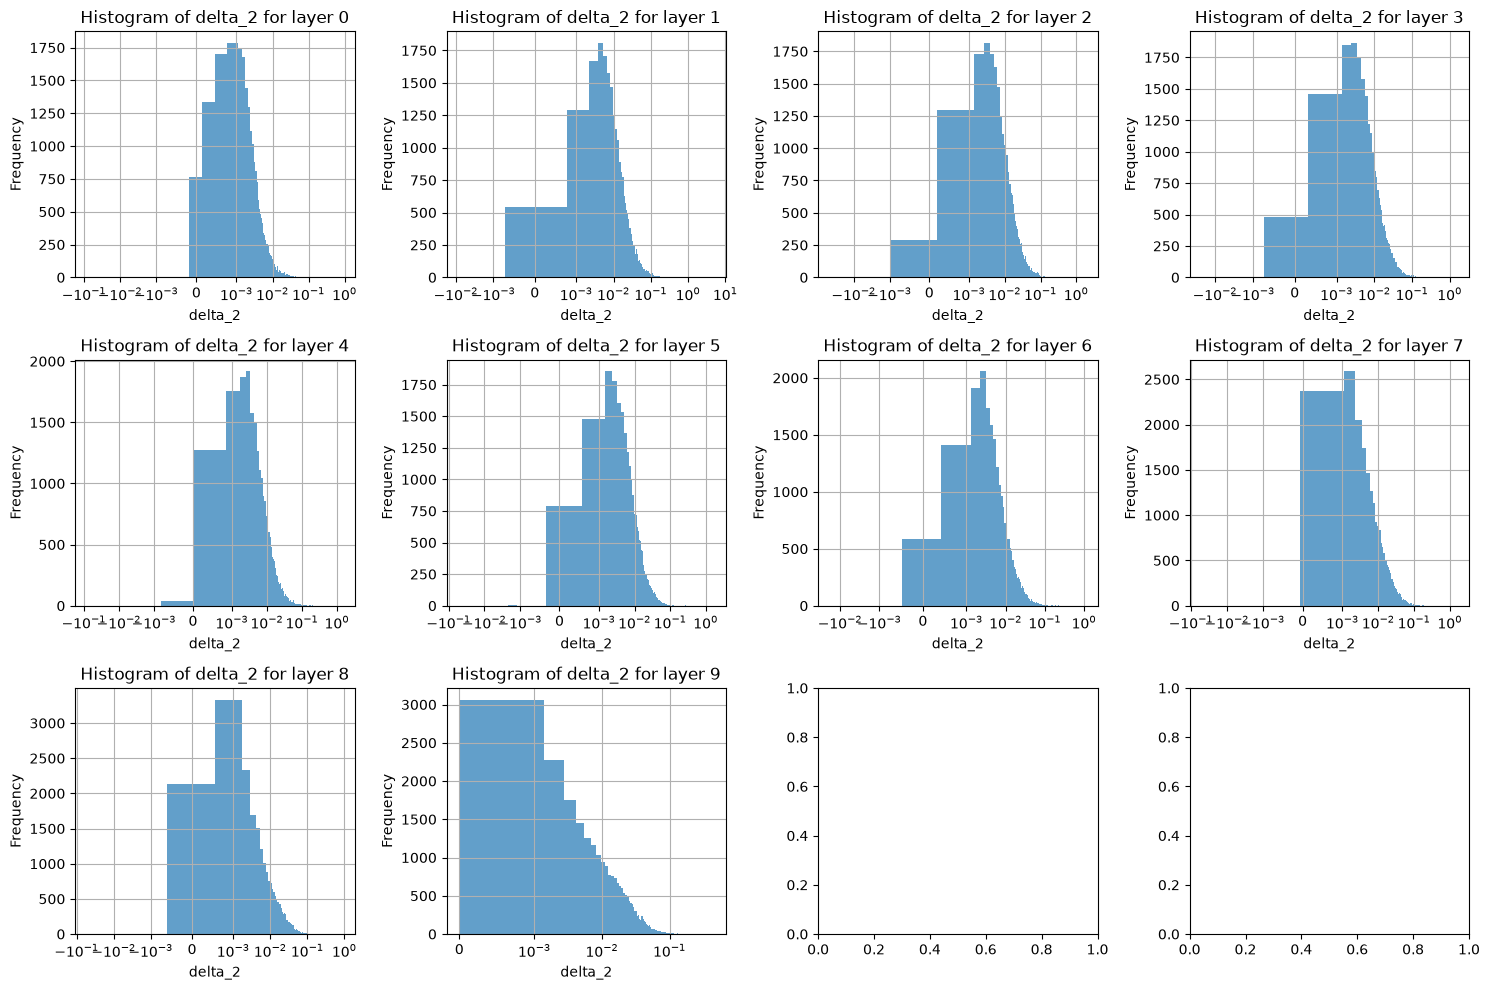

In [17]:
plot_histograms_per_layer(d_df, col="delta_2", save_path=f"{model_figures_dir}/delta_2_histograms_per_layer.png")

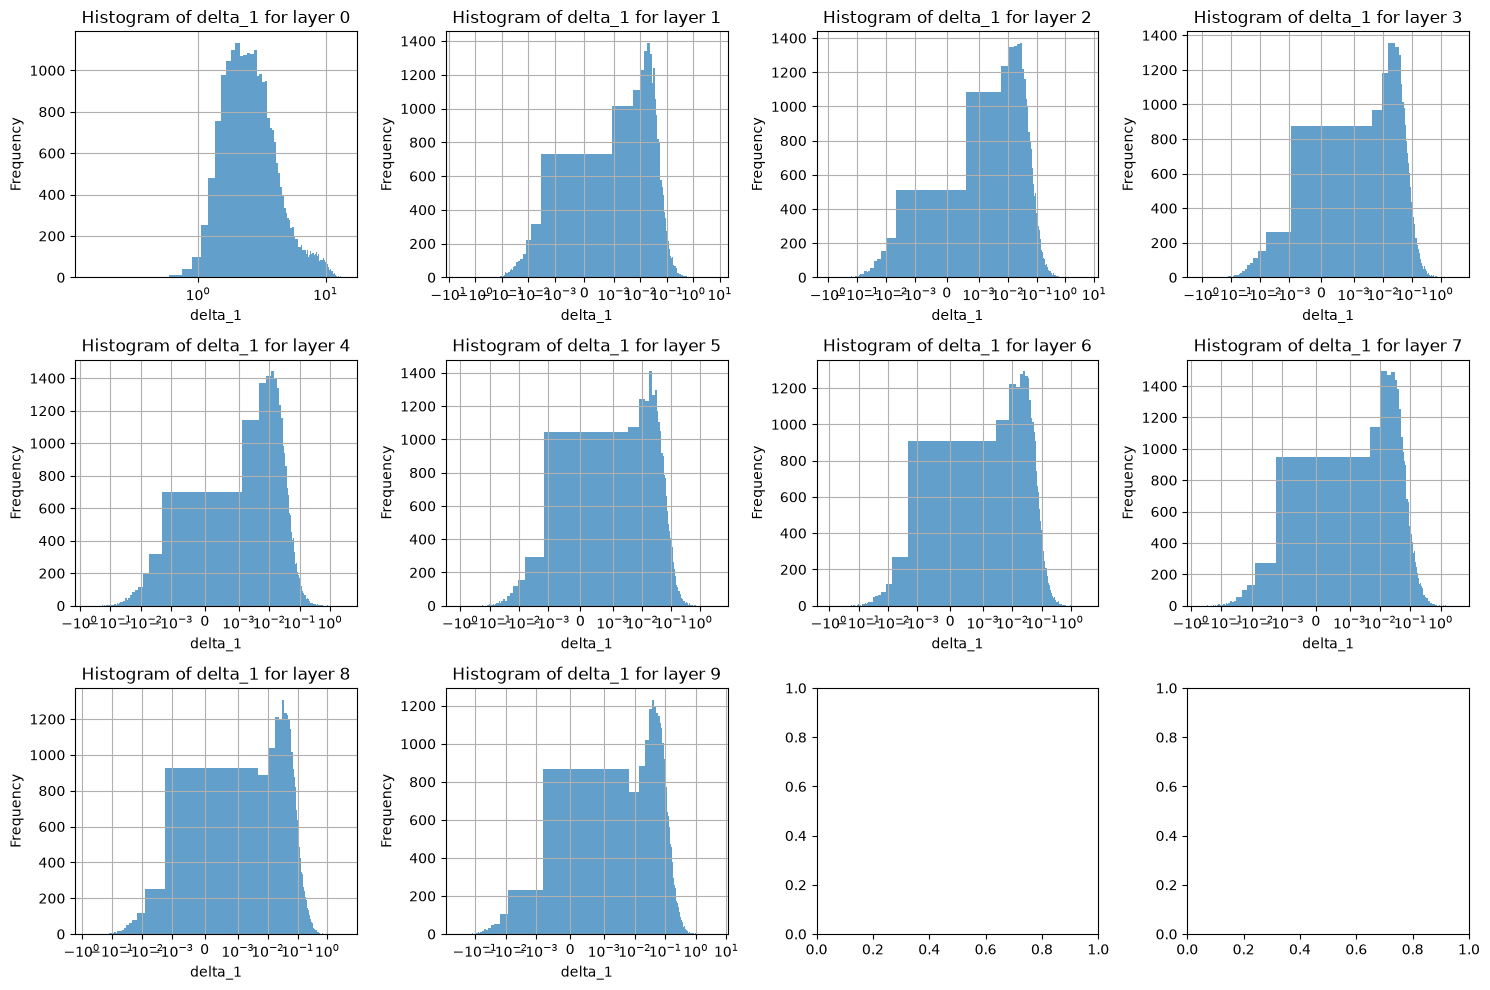

In [18]:
plot_histograms_per_layer(d_df, col="delta_1", save_path=f"{model_figures_dir}/delta_1_histograms_per_layer.png")